# Waste Classification using Image clustering

DATA COLLECTION

In [1]:
from google.colab import drive    # connect a google drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:

!ls "/content/drive/MyDrive/Dataset"

'Waste classfication dataset.zip'


In [3]:
!unzip "/content/drive/MyDrive/Dataset/Waste classfication dataset.zip" -d "/content/waste_dataset"

Archive:  /content/drive/MyDrive/Dataset/Waste classfication dataset.zip
  inflating: /content/waste_dataset/1-Cardboard/Cardboard_1.jpg  
  inflating: /content/waste_dataset/1-Cardboard/Cardboard_10.jpg  
  inflating: /content/waste_dataset/1-Cardboard/Cardboard_100.jpg  
  inflating: /content/waste_dataset/1-Cardboard/Cardboard_101.jpg  
  inflating: /content/waste_dataset/1-Cardboard/Cardboard_102.jpg  
  inflating: /content/waste_dataset/1-Cardboard/Cardboard_103.jpg  
  inflating: /content/waste_dataset/1-Cardboard/Cardboard_104.jpg  
  inflating: /content/waste_dataset/1-Cardboard/Cardboard_105.jpg  
  inflating: /content/waste_dataset/1-Cardboard/Cardboard_106.jpg  
  inflating: /content/waste_dataset/1-Cardboard/Cardboard_107.jpg  
  inflating: /content/waste_dataset/1-Cardboard/Cardboard_108.jpg  
  inflating: /content/waste_dataset/1-Cardboard/Cardboard_109.jpg  
  inflating: /content/waste_dataset/1-Cardboard/Cardboard_11.jpg  
  inflating: /content/waste_dataset/1-Cardboard

EDA (BASIC)

In [4]:
import os
path = "/content/waste_dataset"
os.listdir(path)

['3-Glass',
 '1-Cardboard',
 '9-Vegetation',
 '8-Textile Trash',
 '4-Metal',
 '6-Paper',
 '5-Miscellaneous Trash',
 '2-Food Organics',
 '7-Plastic']

In [5]:
for c in os.listdir(path):
    class_path = os.path.join(path, c)

    print(c, len(os.listdir(class_path)))

3-Glass 420
1-Cardboard 461
9-Vegetation 436
8-Textile Trash 318
4-Metal 790
6-Paper 500
5-Miscellaneous Trash 495
2-Food Organics 411
7-Plastic 921


DATA VISUALIZATION

In [6]:
import matplotlib.pyplot as plt
import cv2

for c in os.listdir(path):
    class_path = os.path.join(path, c)
    img_name = os.listdir(class_path)[0]
    img_path = os.path.join(class_path, img_name)

    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.figure()
    plt.imshow(img)
    plt.title(c)
    plt.axis('off')

Output hidden; open in https://colab.research.google.com to view.

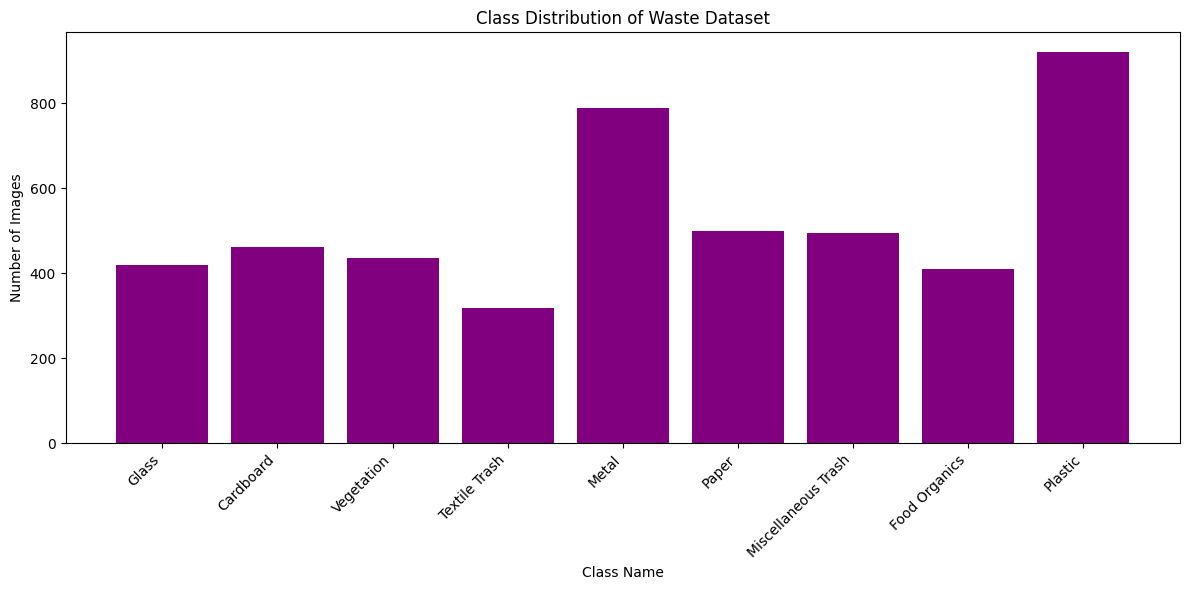

In [7]:
class_names = []
image_counts = []

for c in os.listdir(path):
    class_path = os.path.join(path, c)
    if os.path.isdir(class_path):
        class_names.append(c)
        image_counts.append(len(os.listdir(class_path)))

# Clean class names (optional, remove numbering)
class_names = [c.split('-')[-1] for c in class_names]

# Plot
plt.figure(figsize=(12, 6))
plt.bar(class_names, image_counts, color='purple')
plt.xlabel("Class Name")
plt.ylabel("Number of Images")
plt.title("Class Distribution of Waste Dataset")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

 Class Distribution Bar Chart show clear count of each class.

PRE-PROCESSING

In [8]:
# import Libraries
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import os

In [9]:
#Define Dataset Path
DATASET_PATH = "/content/waste_dataset"
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

In [10]:
#Data Augmentation + Normalization
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=30,
    width_shift_range=0.2,
    height_shift_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    validation_split=0.2
)

In [11]:
#Training Data Generator
train_generator = train_datagen.flow_from_directory(
    DATASET_PATH,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='training',
    shuffle=True
)

Found 3803 images belonging to 9 classes.


In [12]:
#Validation Data Generator
val_generator = train_datagen.flow_from_directory(
    DATASET_PATH,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='validation',
    shuffle=False
)

Found 949 images belonging to 9 classes.


In [13]:
# Verify Class Labels
print(train_generator.class_indices)

{'1-Cardboard': 0, '2-Food Organics': 1, '3-Glass': 2, '4-Metal': 3, '5-Miscellaneous Trash': 4, '6-Paper': 5, '7-Plastic': 6, '8-Textile Trash': 7, '9-Vegetation': 8}


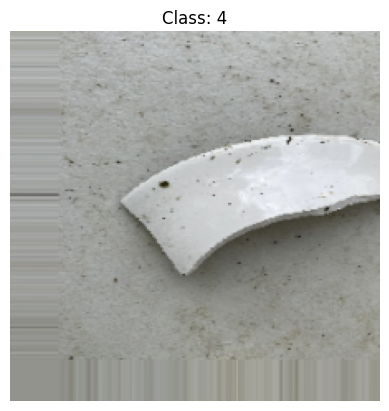

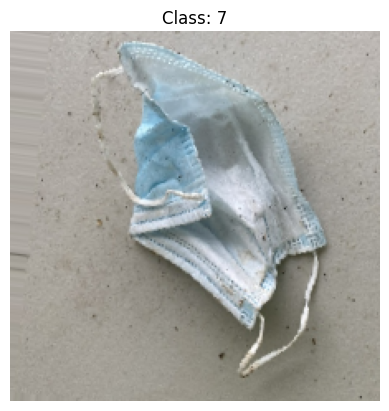

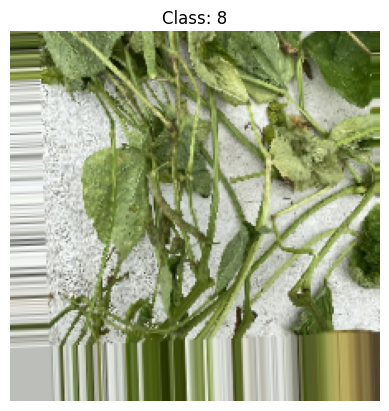

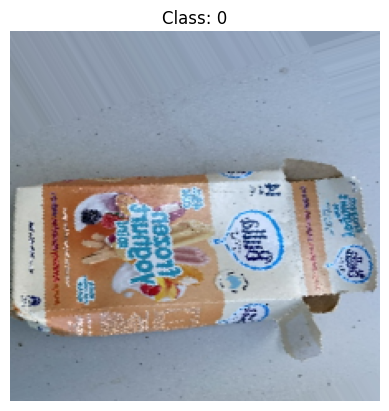

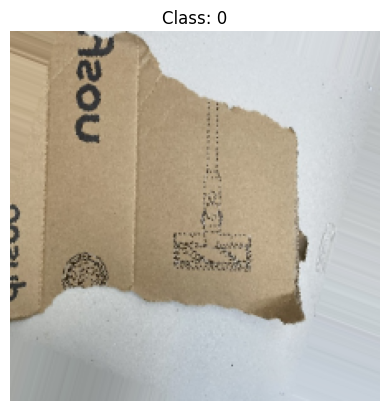

In [14]:
#Visualize Augmented Images
import matplotlib.pyplot as plt
import numpy as np

x_batch, y_batch = next(train_generator)

for i in range(5):
    plt.imshow(x_batch[i])
    plt.title(f"Class: {np.argmax(y_batch[i])}")
    plt.axis("off")
    plt.show()

FEATURE EXTRRACTION

In [15]:
#Import Required Libraries for Feature Extraction
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.models import Model
import numpy as np

In [16]:
#Load Pretrained CNN (Without Classification Head)
base_model = MobileNetV2(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [17]:
#Add Global Pooling Layer
x = base_model.output
x = tf.keras.layers.GlobalAveragePooling2D()(x)

feature_extractor = Model(inputs=base_model.input, outputs=x)

In [18]:
#Freeze CNN Layers
#changes made, last 40 layers unfreezed
for layer in feature_extractor.layers[:-40]:
    layer.trainable = False

for layer in base_model.layers[-40:]:
  layer.trainable = True

In [19]:
#Extract Features from Dataset
def extract_features(generator, model):
    features = []
    labels = []
    filenames = []

    generator.reset()

    for i in range(len(generator)):
        x_batch, y_batch = generator[i]
        feature_batch = model.predict(x_batch, verbose=0)

        features.append(feature_batch)
        labels.append(np.argmax(y_batch, axis=1))
        filenames.extend(generator.filenames[i * generator.batch_size:
                                              (i + 1) * generator.batch_size])

    return np.vstack(features), np.hstack(labels), filenames

In [20]:
#Run Feature Extraction
features, labels, image_paths = extract_features(train_generator, feature_extractor)

In [21]:
#Verify Feature Shape
print("Feature shape:", features.shape)
print("Labels shape:", labels.shape)

Feature shape: (3803, 1280)
Labels shape: (3803,)


In [22]:
#change made, adding PCA

from sklearn.decomposition import PCA

pca = PCA(n_components=10)
features_pca = pca.fit_transform(features)

print("Original:", features.shape)
print("After PCA:", features_pca.shape)

Original: (3803, 1280)
After PCA: (3803, 10)


In [23]:
#Save Extracted Features
np.save("features.npy", features_pca)
np.save("labels.npy", labels)
np.save("image_paths.npy", image_paths)

FEATURE SCALING

In [24]:
#Import Scaler
from sklearn.preprocessing import StandardScaler

In [25]:
#Initialize the Scaler
scaler = StandardScaler()

In [26]:
#Fit and Transform Features
#change made. scalaing pca features. not raw features
features_scaled = scaler.fit_transform(features_pca)

In [27]:
#Verify Scaling (Optional but Good Practice)
print("Mean (approx):", features_scaled.mean())
print("Std (approx):", features_scaled.std())

Mean (approx): -1.2538447e-09
Std (approx): 1.0


In [28]:
#Save Scaled Features
np.save("features_scaled.npy", features_scaled)

IMAGE CLUSTERING (K-Means)

In [29]:
#IMPORT REQUIRED LIBRARIES
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score
import numpy as np

In [30]:
#DECIDE NUMBER OF CLUSTERS (K)
num_clusters = len(train_generator.class_indices)

In [31]:
#APPLY K-MEANS CLUSTERING
kmeans = KMeans(
    n_clusters=num_clusters,
    random_state=42,
    n_init=20 #incresed from 10 to 20
)

cluster_labels = kmeans.fit_predict(features_scaled)

In [32]:
#CHECK OUTPUT SHAPE
print(cluster_labels.shape)

(3803,)


CLUSTER QUALITY EVALUATION

In [33]:
#Silhouette Score
sil_score = silhouette_score(features_scaled, cluster_labels)
print("Silhouette Score:", sil_score)

Silhouette Score: 0.14749002


In [34]:

#Davies–Bouldin Index
db_score = davies_bouldin_score(features_scaled, cluster_labels)
print("Davies-Bouldin Score:", db_score)

#score is the lowest at pca 10 in comparision to PCA being 20,30 or 40. thus 10 is the best in practicality

Davies-Bouldin Score: 1.7181775335527598


PCA components = 10 turns out to be the best choice for our model

ADDING IMAGE CLASSIFICATION MODEL

In [35]:
from tensorflow.keras import layers, models, callbacks

In [36]:
num_classes = len(train_generator.class_indices)

In [37]:
#Base CNN same as before
base_model = MobileNetV2(
    weights = 'imagenet',
    include_top = False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False #staring with frozen layers

In [38]:
#Classification head

x = base_model.output
x = layers.GlobalAveragePooling2D()(x)
x = layers.BatchNormalization()(x)
x = layers.Dense(256, activation = 'relu')(x)
x = layers.Dropout(0.5)(x)

outputs = layers.Dense(num_classes,activation= 'softmax')(x)
model = models.Model(inputs=base_model.input, outputs = outputs)

In [39]:
#compiling model

model.compile(
    optimizer = tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss = 'categorical_crossentropy',
    metrics= ['accuracy']
)

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,593,353 (9.89 MB)

 Trainable params: 332,809 (1.27 MB)

 Non-trainable params: 2,260,544 (8.62 MB)

Training

In [40]:
early_stop = callbacks.EarlyStopping(
    monitor = 'val_loss',
    patience = 5,
    restore_best_weights = True
)

In [41]:
checkpoint = callbacks.ModelCheckpoint(
    "best_model.h5",
    monitor = 'val_accuracy',
    save_best_only = True
)

In [42]:
history = model.fit(
    train_generator,
    validation_data = val_generator,
    epochs = 20,
    callbacks = [early_stop, checkpoint]
)

Epoch 1/20
119/119 ━━━━━━━━━━━━━━━━━━━━ 0s 524ms/step - accuracy: 0.2069 - loss: 2.6929

119/119 ━━━━━━━━━━━━━━━━━━━━ 105s 801ms/step - accuracy: 0.3053 - loss: 2.2325 - val_accuracy: 0.4742 - val_loss: 1.4763
Epoch 2/20
119/119 ━━━━━━━━━━━━━━━━━━━━ 0s 496ms/step - accuracy: 0.5037 - loss: 1.4893

119/119 ━━━━━━━━━━━━━━━━━━━━ 74s 622ms/step - accuracy: 0.5277 - loss: 1.4054 - val_accuracy: 0.5342 - val_loss: 1.3155
Epoch 3/20
119/119 ━━━━━━━━━━━━━━━━━━━━ 0s 474ms/step - accuracy: 0.5766 - loss: 1.2409

119/119 ━━━━━━━━━━━━━━━━━━━━ 71s 596ms/step - accuracy: 0.5861 - loss: 1.2257 - val_accuracy: 0.5701 - val_loss: 1.2699
Epoch 4/20
119/119 ━━━━━━━━━━━━━━━━━━━━ 0s 481ms/step - accuracy: 0.6132 - loss: 1.1529

119/119 ━━━━━━━━━━━━━━━━━━━━ 72s 603ms/step - accuracy: 0.6290 - loss: 1.1076 - val_accuracy: 0.5890 - val_loss: 1.2168
Epoch 5/20
119/119 ━━━━━━━━━━━━━━━━━━━━ 0s 465ms/step - accuracy: 0.6783 - loss: 0.9414

...

119/119 ━━━━━━━━━━━━━━━━━━━━ 84s 604ms/step - accuracy: 0.7436 - loss: 0.7434 - val_accuracy: 0.6354 - val_loss: 1.1400
Epoch 11/20
119/119 ━━━━━━━━━━━━━━━━━━━━ 0s 479ms/step - accuracy: 0.7532 - loss: 0.6987

119/119 ━━━━━━━━━━━━━━━━━━━━ 72s 599ms/step - accuracy: 0.7486 - loss: 0.7050 - val_accuracy: 0.6481 - val_loss: 1.1009
Epoch 12/20
119/119 ━━━━━━━━━━━━━━━━━━━━ 70s 588ms/step - accuracy: 0.7507 - loss: 0.6974 - val_accuracy: 0.6228 - val_loss: 1.1040
Epoch 13/20
119/119 ━━━━━━━━━━━━━━━━━━━━ 70s 583ms/step - accuracy: 0.7620 - loss: 0.6731 - val_accuracy: 0.6333 - val_loss: 1.0868
Epoch 14/20
119/119 ━━━━━━━━━━━━━━━━━━━━ 69s 582ms/step - accuracy: 0.7657 - loss: 0.6533 - val_accuracy: 0.6322 - val_loss: 1.0830
Epoch 15/20
119/119 ━━━━━━━━━━━━━━━━━━━━ 71s 593ms/step - accuracy: 0.7849 - loss: 0.5994 - val_accuracy: 0.6407 - val_loss: 1.1306
Epoch 16/20
119/119 ━━━━━━━━━━━━━━━━━━━━ 0s 465ms/step - accuracy: 0.7800 - loss: 0.6241

119/119 ━━━━━━━━━━━━━━━━━━━━ 69s 582ms/step - accuracy: 0.7875 - loss: 0.6074 - val_accuracy: 0.6491 - val_loss: 1.0606
Epoch 17/20
119/119 ━━━━━━━━━━━━━━━━━━━━ 0s 454ms/step - accuracy: 0.7913 - loss: 0.6030

119/119 ━━━━━━━━━━━━━━━━━━━━ 68s 573ms/step - accuracy: 0.7957 - loss: 0.5866 - val_accuracy: 0.6533 - val_loss: 1.0641
Epoch 18/20
119/119 ━━━━━━━━━━━━━━━━━━━━ 0s 454ms/step - accuracy: 0.8089 - loss: 0.5320

119/119 ━━━━━━━━━━━━━━━━━━━━ 82s 572ms/step - accuracy: 0.7986 - loss: 0.5628 - val_accuracy: 0.6575 - val_loss: 1.0690
Epoch 19/20
119/119 ━━━━━━━━━━━━━━━━━━━━ 69s 574ms/step - accuracy: 0.8004 - loss: 0.5703 - val_accuracy: 0.6481 - val_loss: 1.0546
Epoch 20/20
119/119 ━━━━━━━━━━━━━━━━━━━━ 68s 572ms/step - accuracy: 0.8186 - loss: 0.5286 - val_accuracy: 0.6533 - val_loss: 1.0667


Evaluation ( Accuracy, Loss, Confusion matrix)

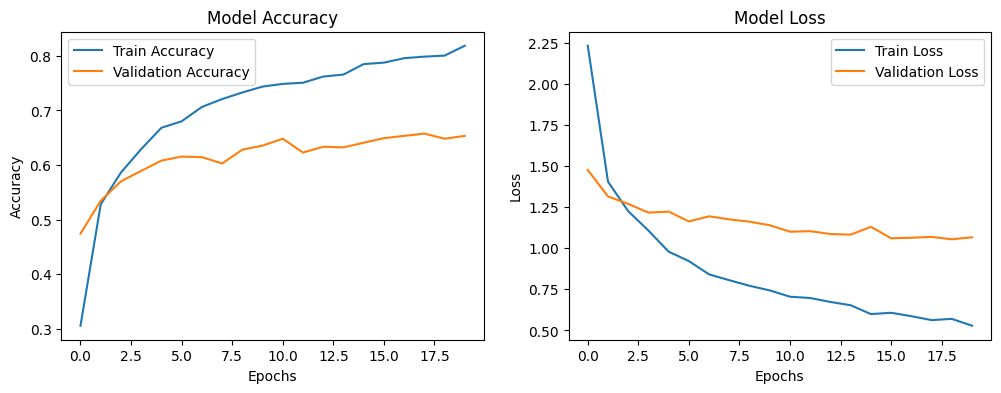

In [43]:

plt.figure(figsize=(12,4))

plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label= 'Validation Accuracy')
plt.title("Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()

#loss plot

plt.subplot(1,2,2)
plt.plot(history.history['loss'], label = 'Train Loss')
plt.plot(history.history['val_loss'], label = 'Validation Loss')
plt.title("Model Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

plt.show()



Confusion Matrix

In [44]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

30/30 ━━━━━━━━━━━━━━━━━━━━ 23s 600ms/step


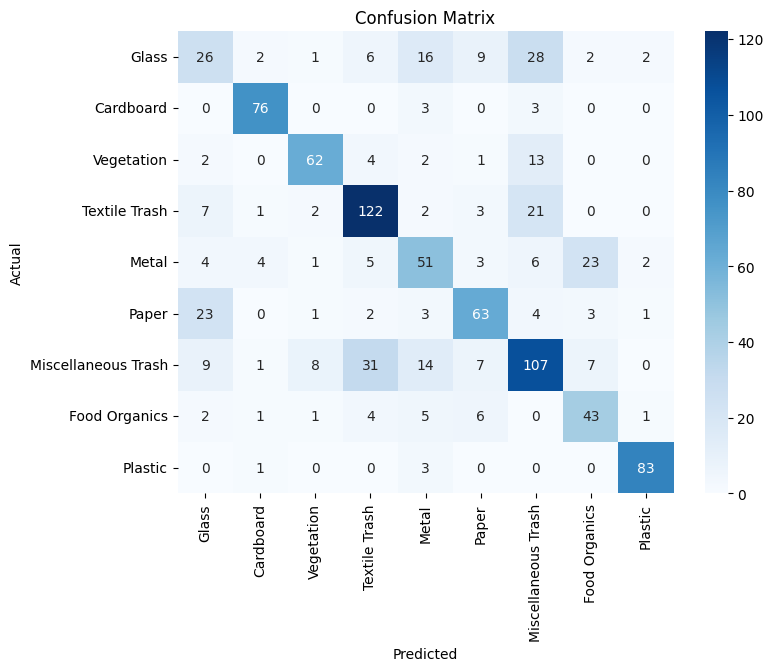

                     precision    recall  f1-score   support

              Glass       0.36      0.28      0.32        92
          Cardboard       0.88      0.93      0.90        82
         Vegetation       0.82      0.74      0.78        84
      Textile Trash       0.70      0.77      0.73       158
              Metal       0.52      0.52      0.52        99
              Paper       0.68      0.63      0.66       100
Miscellaneous Trash       0.59      0.58      0.58       184
      Food Organics       0.55      0.68      0.61        63
            Plastic       0.93      0.95      0.94        87

           accuracy                           0.67       949
          macro avg       0.67      0.68      0.67       949
       weighted avg       0.66      0.67      0.66       949



In [45]:
val_generator.reset()
preds = model.predict(val_generator)
y_pred = np.argmax(preds, axis = 1)
y_true = val_generator.classes

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt = 'd',
            xticklabels=class_names,
            yticklabels=class_names,
            cmap='Blues')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

print(classification_report(y_true, y_pred, target_names=class_names))


In [46]:
model.save("Waste_classification_model.keras")

In [47]:
def predict_image(img_path, model):
  img = tf.keras.preprocessing.image.load_img(
      img_path, target_size=(224,224)
  )
  img_array = tf.keras.preprocessing.image.img_to_array(img)
  img_array = img_array / 255.0
  img_array = np.expand_dims(img_array, axis=0)

  preds = model.predict(img_array)
  class_idx = np.argmax(preds)
  return class_names[class_idx]


Image upload and prediction using collab

In [48]:
from tensorflow.keras.models import load_model
model = load_model("best_model.h5")

In [67]:
#To upload image
from google.colab import files

upload = files.upload()

Saving image 2.jfif to image 2 (1).jfif


preprocessing image

In [68]:
import cv2
import numpy as np
from tensorflow.keras.preprocessing.image import img_to_array

def preprocess_image(img_path):
  img = cv2.imread(img_path)
  img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
  img = cv2.resize(img, (224, 224))
  img = img/255.0
  img = np.expand_dims(img, axis = 0)
  return img

predicting the class of waste

In [69]:
#getting uploaded image
image_path = list(upload.keys())[0]

#preprocessing the uploaded image
processed_img = preprocess_image(image_path)


#predicting the class of uploaded image
predictions = model.predict(processed_img)
predicted_class = np.argmax(predictions )

#mapping class label
class_labels = {v:k for k, v in train_generator.class_indices.items()}

print("Predicted class is ", class_labels[predicted_class])

1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step
Predicted class is  1-Cardboard


In [70]:
#Filter to prdict if the waste is recyclable
recyclable = {
    "4-Metal": "Recyclable",
    "3-Glass": "Recyclable",
    "7-Plastic":"Recyclable",
    "6-Paper": "Recyclable",
    "1-Cardboard": "Recyclable",
    "9-Vegetation": "Biodegradable",
    "2-Food Organics": "Non=Recyclable",
    "8-Textile Trash": "Non-recyclable",
    "5-Miscellaneous Trash": "Non-Recyclable"

}

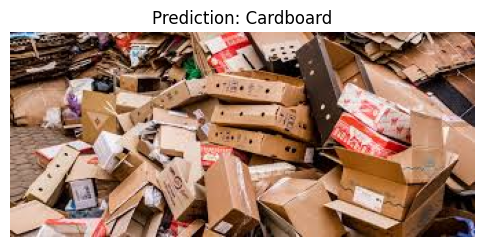

Predicted Class : Cardboard
Recyclability   : Recyclable


In [71]:
import cv2
import matplotlib.pyplot as plt

# Recyclability dictionary
recyclable = {
    "cardboard": "Recyclable",
    "paper": "Recyclable",
    "plastic": "Recyclable",
    "glass": "Recyclable",
    "metal": "Recyclable",
    "trash": "Non-Recyclable"
}

# Read image
img = cv2.imread(image_path)

if img is None:
    print("Error: Image not found!")
else:
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # Original predicted label (e.g. "3-Glass")
    predicted_label = class_labels[predicted_class]

    # Clean label (convert "3-Glass" -> "glass")
    clean_label = predicted_label.split("-")[-1].strip().lower()

    # Get recyclability
    recyclability = recyclable.get(clean_label, "Unknown")

    # Display image
    plt.figure(figsize=(6,6))
    plt.imshow(img)
    plt.axis("off")
    plt.title(f"Prediction: {clean_label.title()}")
    plt.show()

    # Print results
    print("=" * 40)
    print("Predicted Class :", clean_label.title())
    print("Recyclability   :", recyclability)
    print("=" * 40)

In [61]:
model.save("best_model.h5")


In [62]:
import pickle

class_names = list(train_generator.class_indices.keys())

with open("class_names.pkl", "wb") as f:
    pickle.dump(class_names, f)


print(class_names)


['1-Cardboard', '2-Food Organics', '3-Glass', '4-Metal', '5-Miscellaneous Trash', '6-Paper', '7-Plastic', '8-Textile Trash', '9-Vegetation']


In [63]:
from tensorflow.keras.models import load_model

model = load_model("best_model.h5")
print("✅ Trained model loaded successfully")


✅ Trained model loaded successfully


In [64]:
model.evaluate(val_generator)


30/30 ━━━━━━━━━━━━━━━━━━━━ 22s 559ms/step - accuracy: 0.6575 - loss: 1.0447


[1.0447250604629517, 0.6575342416763306]

In [65]:
model.predict(processed_img)


1/1 ━━━━━━━━━━━━━━━━━━━━ 6s 6s/step


array([[7.2822315e-01, 3.0174339e-03, 1.5290092e-04, 3.7682851e-04,
        2.5799956e-02, 2.4055998e-01, 1.6486425e-03, 3.9329971e-05,
        1.8187921e-04]], dtype=float32)

In [66]:
model = tf.keras.models.load_model("best_model.h5")
